# Проверка библиотек и импорты

In [1]:
import importlib

libs = {
    "torch":          "PyTorch",
    "torchvision":    "TorchVision",
    "PIL":            "Pillow",
    "matplotlib":     "Matplotlib",
    "numpy":          "NumPy",
    "sklearn":        "scikit-learn",
}
for pkg, name in libs.items():
    try:
        mod = importlib.import_module(pkg)
        ver = getattr(mod, "__version__", "?")
        print(f"[OK]  {name}: {ver}")
    except ImportError:
        print(f"[НЕТ] {name}: установите через pip")

[OK]  PyTorch: 2.2.2+rocm5.7


/home/abonentvneseti/.pyenv/versions/3.11.16/lib/python3.11/site-packages/transformers/utils/generic.py:441: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  _torch_pytree._register_pytree_node(


[OK]  TorchVision: 0.17.2+rocm5.7
[OK]  Pillow: 12.3.0
[OK]  Matplotlib: 3.9.0
[OK]  NumPy: 1.26.4
[OK]  scikit-learn: 1.5.0


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import matplotlib.pyplot as plt
import numpy as np
import time, copy
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__}")
print(f"Устройство: {device}")

PyTorch: 2.2.2+rocm5.7
Устройство: cuda


# Загрузка CIFAR-10

In [3]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
NUM_TRAIN = 10000
NUM_TEST = 1000
NUM_EPOCHS = 10

train_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomCrop(224, padding=8),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
val_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds_full = torchvision.datasets.CIFAR10(root="./cifar", train=True,  download=True, transform=train_transform)
val_ds_full   = torchvision.datasets.CIFAR10(root="./cifar", train=False, download=True, transform=val_transform)

train_ds = Subset(train_ds_full, list(range(min(NUM_TRAIN, len(train_ds_full)))))
val_ds   = Subset(val_ds_full,   list(range(min(NUM_TEST, len(val_ds_full)))))

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=0)

CLASS_NAMES = train_ds_full.classes
NUM_CLASSES = len(CLASS_NAMES)
print(f"Классы ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"Train: {len(train_ds)}, Val: {len(val_ds)}")

Files already downloaded and verified
Files already downloaded and verified
Классы (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train: 10000, Val: 1000


# Функция обучения и анализа

In [4]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        out = model(images)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        _, preds = out.max(1)
        correct += preds.eq(labels).sum().item()
        total   += labels.size(0)
    return total_loss / total, correct / total


def eval_epoch(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            out = model(images)
            loss = criterion(out, labels)
            total_loss += loss.item() * images.size(0)
            _, preds = out.max(1)
            correct += preds.eq(labels).sum().item()
            total   += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return total_loss / total, correct / total, all_preds, all_labels


def build_optimizer(model, mode, base_lr=1e-3):
    if mode == "ft":
        backbone, head = [], []
        for n, p in model.named_parameters():
            if not p.requires_grad:
                continue
            if "fc" in n or "classifier" in n:
                head.append(p)
            else:
                backbone.append(p)
        return optim.Adam([
            {"params": backbone, "lr": base_lr * 0.1},
            {"params": head,     "lr": base_lr},
        ])
    return optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=base_lr)


def run_training(model, name, mode, num_epochs=3, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = build_optimizer(model, mode, base_lr=lr)
    scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, patience=2, factor=0.1)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    t0 = time.time()
    for epoch in range(num_epochs):
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer)
        vl_loss, vl_acc, _, _ = eval_epoch(model, val_loader, criterion)
        scheduler.step(vl_loss)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(vl_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(vl_acc)
        print(f"  [{name}] Epoch {epoch+1}/{num_epochs} | train={tr_acc:.3f} | val={vl_acc:.3f}")
    dt = time.time() - t0
    print(f"  [{name}] Время обучения: {dt:.1f} сек")
    return model, history, dt

In [5]:
def analyze_experiment(exp_name, results):
    """results: список dict {name, hist, acc, dt, preds, labels}."""
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    for r in results:
        axes[0].plot(range(1, len(r["hist"]["val_acc"]) + 1),
                     r["hist"]["val_acc"], marker="o", label=r["name"])
    axes[0].set_title(f"{exp_name}: Val Accuracy")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("val acc")
    axes[0].legend(); axes[0].grid(alpha=0.3)

    best = max(results, key=lambda x: x["acc"])
    eps = range(1, len(best["hist"]["train_acc"]) + 1)
    axes[1].plot(eps, best["hist"]["train_acc"], marker="o", label="train")
    axes[1].plot(eps, best["hist"]["val_acc"],   marker="s", label="val")
    axes[1].set_title(f"{exp_name}: лучшее = {best['name']}")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
    axes[1].legend(); axes[1].grid(alpha=0.3)

    cm = confusion_matrix(best["labels"], best["preds"], labels=range(NUM_CLASSES))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(ax=axes[2], colorbar=False, cmap="Blues")
    axes[2].set_title(f"CM: {best['name']}")
    plt.setp(axes[2].get_xticklabels(), rotation=45, ha="right")

    plt.tight_layout(); plt.show()

    print(f"\n{exp_name} - итоги:")
    print(f"{'Модель':<25} | {'Val Acc':>8} | {'Время, сек':>12}")
    print("-" * 55)
    for r in sorted(results, key=lambda x: -x["acc"]):
        marker = " <<< лучший" if r["name"] == best["name"] else ""
        print(f"{r['name']:<25} | {r['acc']:>8.4f} | {r['dt']:>12.1f}{marker}")
    return best

# Модели

In [6]:
def build_resnet18(mode):
    if mode == "scratch":
        m = models.resnet18(weights=None)
    else:
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    if mode == "fe":
        for p in m.parameters(): p.requires_grad = False
        for p in m.fc.parameters(): p.requires_grad = True
    elif mode == "ft":
        for p in m.parameters(): p.requires_grad = False
        for p in m.layer4.parameters(): p.requires_grad = True
        for p in m.fc.parameters():    p.requires_grad = True
    return m


def build_densenet121(mode):
    if mode == "scratch":
        m = models.densenet121(weights=None)
    else:
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
    m.classifier = nn.Linear(m.classifier.in_features, NUM_CLASSES)
    if mode == "fe":
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier.parameters(): p.requires_grad = True
    elif mode == "ft":
        for p in m.parameters(): p.requires_grad = False
        for p in m.features.denseblock4.parameters(): p.requires_grad = True
        for p in m.features.norm5.parameters():       p.requires_grad = True
        for p in m.classifier.parameters():           p.requires_grad = True
    return m


def build_efficientnet_b0(mode):
    if mode == "scratch":
        m = models.efficientnet_b0(weights=None)
    else:
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
    if mode == "fe":
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier.parameters(): p.requires_grad = True
    elif mode == "ft":
        for p in m.parameters(): p.requires_grad = False
        for p in m.features[-1].parameters(): p.requires_grad = True
        for p in m.classifier.parameters():   p.requires_grad = True
    return m


def build_efficientnet_b3(mode):
    if mode == "scratch":
        m = models.efficientnet_b3(weights=None)
    else:
        m = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
    if mode == "fe":
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier.parameters(): p.requires_grad = True
    elif mode == "ft":
        for p in m.parameters(): p.requires_grad = False
        for p in m.features[-1].parameters(): p.requires_grad = True
        for p in m.classifier.parameters():   p.requires_grad = True
    return m

# 1. Feature Extraction

In [7]:
criterion_eval = nn.CrossEntropyLoss()
results_fe = []

# 1.1 ResNet-18
print("\n[FE] ResNet-18")
m = build_resnet18("fe")
m, hist, dt = run_training(m, "ResNet-18", mode="fe", num_epochs=NUM_EPOCHS, lr=1e-3)
_, acc, preds, labels = eval_epoch(m, val_loader, criterion_eval)
results_fe.append({"name": "ResNet-18", "hist": hist, "acc": acc, "dt": dt,
                   "preds": preds, "labels": labels})

# 1.2 DenseNet-121
print("\n[FE] DenseNet-121")
m = build_densenet121("fe")
m, hist, dt = run_training(m, "DenseNet-121", mode="fe", num_epochs=NUM_EPOCHS, lr=1e-3)
_, acc, preds, labels = eval_epoch(m, val_loader, criterion_eval)
results_fe.append({"name": "DenseNet-121", "hist": hist, "acc": acc, "dt": dt,
                   "preds": preds, "labels": labels})

# 1.3 EfficientNet-B0
print("\n[FE] EfficientNet-B0")
m = build_efficientnet_b0("fe")
m, hist, dt = run_training(m, "EfficientNet-B0", mode="fe", num_epochs=NUM_EPOCHS, lr=1e-3)
_, acc, preds, labels = eval_epoch(m, val_loader, criterion_eval)
results_fe.append({"name": "EfficientNet-B0", "hist": hist, "acc": acc, "dt": dt,
                   "preds": preds, "labels": labels})


[FE] ResNet-18
  [ResNet-18] Epoch 1/10 | train=0.624 | val=0.734
  [ResNet-18] Epoch 2/10 | train=0.739 | val=0.750
  [ResNet-18] Epoch 3/10 | train=0.757 | val=0.777
  [ResNet-18] Epoch 4/10 | train=0.765 | val=0.767
  [ResNet-18] Epoch 5/10 | train=0.774 | val=0.777
  [ResNet-18] Epoch 6/10 | train=0.775 | val=0.793
  [ResNet-18] Epoch 7/10 | train=0.780 | val=0.781
  [ResNet-18] Epoch 8/10 | train=0.782 | val=0.781
  [ResNet-18] Epoch 9/10 | train=0.785 | val=0.780
  [ResNet-18] Epoch 10/10 | train=0.802 | val=0.795
  [ResNet-18] Время обучения: 184.5 сек

[FE] DenseNet-121
  [DenseNet-121] Epoch 1/10 | train=0.644 | val=0.751
  [DenseNet-121] Epoch 2/10 | train=0.759 | val=0.768
  [DenseNet-121] Epoch 3/10 | train=0.773 | val=0.741
  [DenseNet-121] Epoch 4/10 | train=0.785 | val=0.787
  [DenseNet-121] Epoch 5/10 | train=0.785 | val=0.787
  [DenseNet-121] Epoch 6/10 | train=0.794 | val=0.794
  [DenseNet-121] Epoch 7/10 | train=0.797 | val=0.793
  [DenseNet-121] Epoch 8/10 | train=

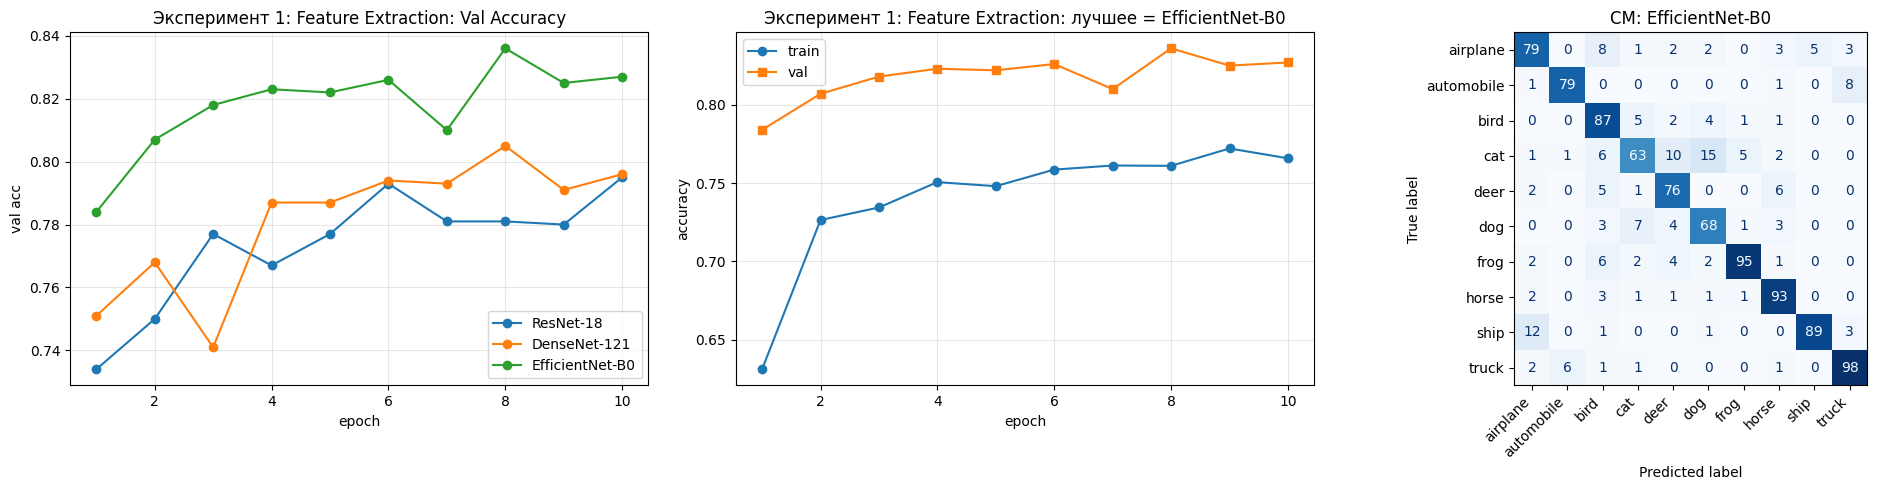


Эксперимент 1: Feature Extraction - итоги:
Модель                    |  Val Acc |   Время, сек
-------------------------------------------------------
EfficientNet-B0           |   0.8270 |        291.0 <<< лучший
DenseNet-121              |   0.7960 |        343.0
ResNet-18                 |   0.7950 |        184.5


In [8]:
best_fe = analyze_experiment("Эксперимент 1: Feature Extraction", results_fe)

# 1. Fine-Tuning

In [9]:
results_ft = []

# 2.1 ResNet-18
print("\n[FT] ResNet-18")
m = build_resnet18("ft")
m, hist, dt = run_training(m, "ResNet-18", mode="ft", num_epochs=NUM_EPOCHS, lr=1e-3)
_, acc, preds, labels = eval_epoch(m, val_loader, criterion_eval)
results_ft.append({"name": "ResNet-18", "hist": hist, "acc": acc, "dt": dt,
                   "preds": preds, "labels": labels})

# 2.2 DenseNet-121
print("\n[FT] DenseNet-121")
m = build_densenet121("ft")
m, hist, dt = run_training(m, "DenseNet-121", mode="ft", num_epochs=NUM_EPOCHS, lr=1e-3)
_, acc, preds, labels = eval_epoch(m, val_loader, criterion_eval)
results_ft.append({"name": "DenseNet-121", "hist": hist, "acc": acc, "dt": dt,
                   "preds": preds, "labels": labels})

# 2.3 EfficientNet-B0
print("\n[FT] EfficientNet-B0")
m = build_efficientnet_b0("ft")
m, hist, dt = run_training(m, "EfficientNet-B0", mode="ft", num_epochs=NUM_EPOCHS, lr=1e-3)
_, acc, preds, labels = eval_epoch(m, val_loader, criterion_eval)
results_ft.append({"name": "EfficientNet-B0", "hist": hist, "acc": acc, "dt": dt,
                   "preds": preds, "labels": labels})


[FT] ResNet-18
  [ResNet-18] Epoch 1/10 | train=0.777 | val=0.850
  [ResNet-18] Epoch 2/10 | train=0.886 | val=0.872
  [ResNet-18] Epoch 3/10 | train=0.914 | val=0.875
  [ResNet-18] Epoch 4/10 | train=0.930 | val=0.879
  [ResNet-18] Epoch 5/10 | train=0.941 | val=0.872
  [ResNet-18] Epoch 6/10 | train=0.954 | val=0.890
  [ResNet-18] Epoch 7/10 | train=0.963 | val=0.904
  [ResNet-18] Epoch 8/10 | train=0.968 | val=0.891
  [ResNet-18] Epoch 9/10 | train=0.973 | val=0.880
  [ResNet-18] Epoch 10/10 | train=0.970 | val=0.883
  [ResNet-18] Время обучения: 231.3 сек

[FT] DenseNet-121
  [DenseNet-121] Epoch 1/10 | train=0.740 | val=0.853
  [DenseNet-121] Epoch 2/10 | train=0.848 | val=0.860
  [DenseNet-121] Epoch 3/10 | train=0.881 | val=0.881
  [DenseNet-121] Epoch 4/10 | train=0.897 | val=0.880
  [DenseNet-121] Epoch 5/10 | train=0.912 | val=0.892
  [DenseNet-121] Epoch 6/10 | train=0.928 | val=0.890
  [DenseNet-121] Epoch 7/10 | train=0.938 | val=0.883
  [DenseNet-121] Epoch 8/10 | train=

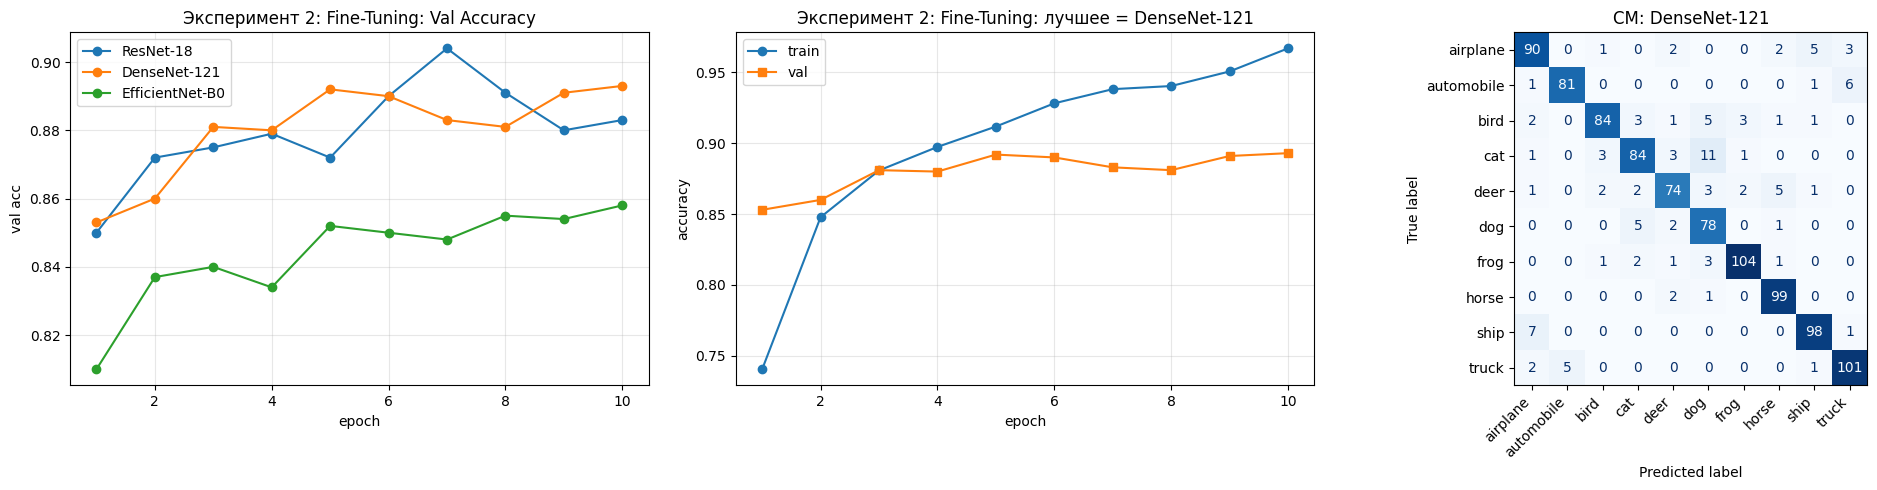


Эксперимент 2: Fine-Tuning - итоги:
Модель                    |  Val Acc |   Время, сек
-------------------------------------------------------
DenseNet-121              |   0.8930 |        357.8 <<< лучший
ResNet-18                 |   0.8830 |        231.3
EfficientNet-B0           |   0.8580 |        279.8


In [10]:
best_ft = analyze_experiment("Эксперимент 2: Fine-Tuning", results_ft)

# 3. From Scratch

In [11]:
results_scratch = []

# 3.1 ResNet-18
print("\n[Scratch] ResNet-18")
m = build_resnet18("scratch")
m, hist, dt = run_training(m, "ResNet-18", mode="scratch", num_epochs=NUM_EPOCHS, lr=1e-3)
_, acc, preds, labels = eval_epoch(m, val_loader, criterion_eval)
results_scratch.append({"name": "ResNet-18", "hist": hist, "acc": acc, "dt": dt,
                        "preds": preds, "labels": labels})

# 3.2 DenseNet-121
print("\n[Scratch] DenseNet-121")
m = build_densenet121("scratch")
m, hist, dt = run_training(m, "DenseNet-121", mode="scratch", num_epochs=NUM_EPOCHS, lr=1e-3)
_, acc, preds, labels = eval_epoch(m, val_loader, criterion_eval)
results_scratch.append({"name": "DenseNet-121", "hist": hist, "acc": acc, "dt": dt,
                        "preds": preds, "labels": labels})

# 3.3 EfficientNet-B0
print("\n[Scratch] EfficientNet-B0")
m = build_efficientnet_b0("scratch")
m, hist, dt = run_training(m, "EfficientNet-B0", mode="scratch", num_epochs=NUM_EPOCHS, lr=1e-3)
_, acc, preds, labels = eval_epoch(m, val_loader, criterion_eval)
results_scratch.append({"name": "EfficientNet-B0", "hist": hist, "acc": acc, "dt": dt,
                        "preds": preds, "labels": labels})


[Scratch] ResNet-18


MIOpen(HIP): Warning [FindSolutionImpl] Invalid config loaded from Perf Db: ConvBinWinogradRxSf3x2: 72. Performance may degrade.


  [ResNet-18] Epoch 1/10 | train=0.294 | val=0.389
  [ResNet-18] Epoch 2/10 | train=0.419 | val=0.440
  [ResNet-18] Epoch 3/10 | train=0.500 | val=0.529
  [ResNet-18] Epoch 4/10 | train=0.564 | val=0.605
  [ResNet-18] Epoch 5/10 | train=0.622 | val=0.597
  [ResNet-18] Epoch 6/10 | train=0.666 | val=0.680
  [ResNet-18] Epoch 7/10 | train=0.694 | val=0.645
  [ResNet-18] Epoch 8/10 | train=0.725 | val=0.693
  [ResNet-18] Epoch 9/10 | train=0.754 | val=0.702
  [ResNet-18] Epoch 10/10 | train=0.779 | val=0.748
  [ResNet-18] Время обучения: 365.9 сек

[Scratch] DenseNet-121
  [DenseNet-121] Epoch 1/10 | train=0.284 | val=0.332
  [DenseNet-121] Epoch 2/10 | train=0.418 | val=0.389
  [DenseNet-121] Epoch 3/10 | train=0.498 | val=0.490
  [DenseNet-121] Epoch 4/10 | train=0.551 | val=0.600
  [DenseNet-121] Epoch 5/10 | train=0.604 | val=0.596
  [DenseNet-121] Epoch 6/10 | train=0.637 | val=0.621
  [DenseNet-121] Epoch 7/10 | train=0.670 | val=0.628
  [DenseNet-121] Epoch 8/10 | train=0.697 | val

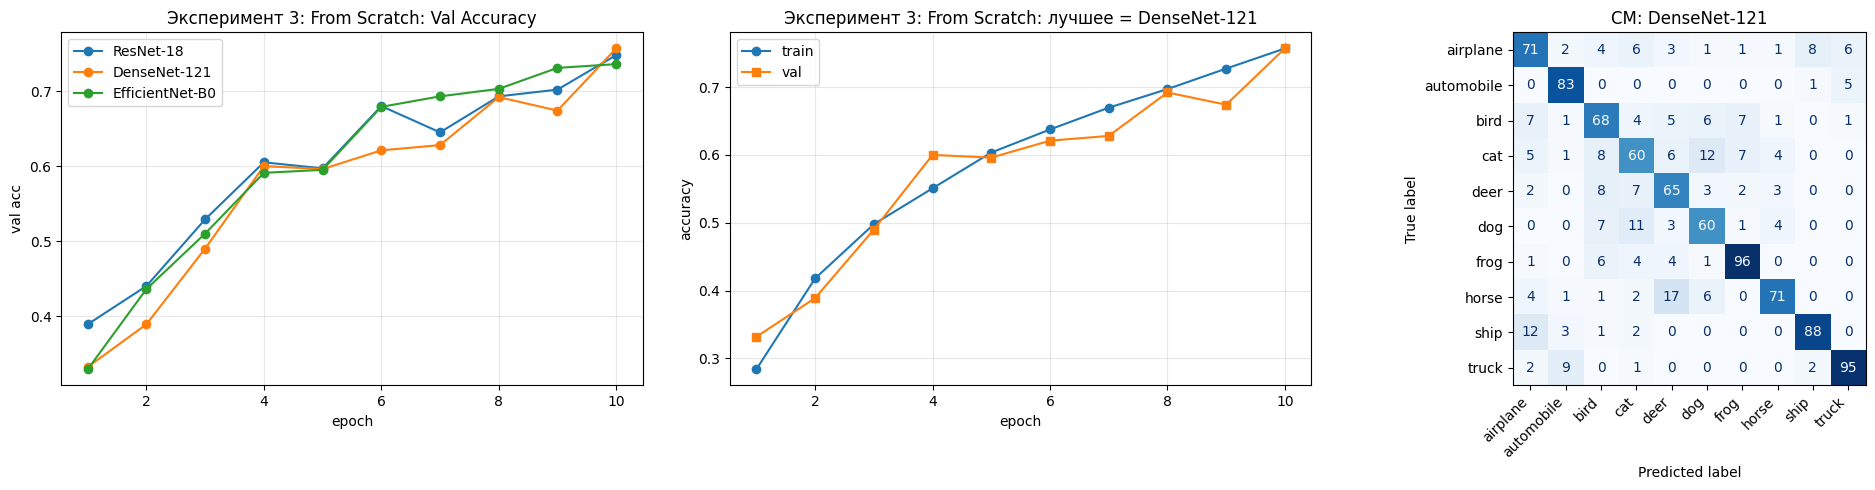


Эксперимент 3: From Scratch - итоги:
Модель                    |  Val Acc |   Время, сек
-------------------------------------------------------
DenseNet-121              |   0.7570 |        811.6 <<< лучший
ResNet-18                 |   0.7480 |        365.9
EfficientNet-B0           |   0.7360 |        733.8


In [12]:
best_scratch = analyze_experiment("Эксперимент 3: From Scratch", results_scratch)

# Итог

In [13]:
def n_params(model_name):
    return model_name

all_results = []
# FE
for r in results_fe:
    all_results.append((f"FE  {r['name']}", r["acc"], r["dt"]))

# FT
for r in results_ft:
    all_results.append((f"FT  {r['name']}", r["acc"], r["dt"]))
# Scratch
for r in results_scratch:
    all_results.append((f"Scr {r['name']}", r["acc"], r["dt"]))

all_results.sort(key=lambda x: -x[1])

print(f"{'Конфигурация':<32} | {'Val Acc':>8} | {'Время, сек':>12}")
print("-" * 62)
for name, acc, dt in all_results:
    print(f"{name:<32} | {acc:>8.4f} | {dt:>12.1f}")

best_overall = all_results[0]
print(f"\nЛучшая конфигурация: {best_overall[0]} (acc={best_overall[1]:.4f})")

Конфигурация                     |  Val Acc |   Время, сек
--------------------------------------------------------------
FT  DenseNet-121                 |   0.8930 |        357.8
FT  ResNet-18                    |   0.8830 |        231.3
FT  EfficientNet-B0              |   0.8580 |        279.8
FE  EfficientNet-B0              |   0.8270 |        291.0
FE  DenseNet-121                 |   0.7960 |        343.0
FE  ResNet-18                    |   0.7950 |        184.5
Scr DenseNet-121                 |   0.7570 |        811.6
Scr ResNet-18                    |   0.7480 |        365.9
Scr EfficientNet-B0              |   0.7360 |        733.8

Лучшая конфигурация: FT  DenseNet-121 (acc=0.8930)


# 4. Анализ ошибок лучшей модели

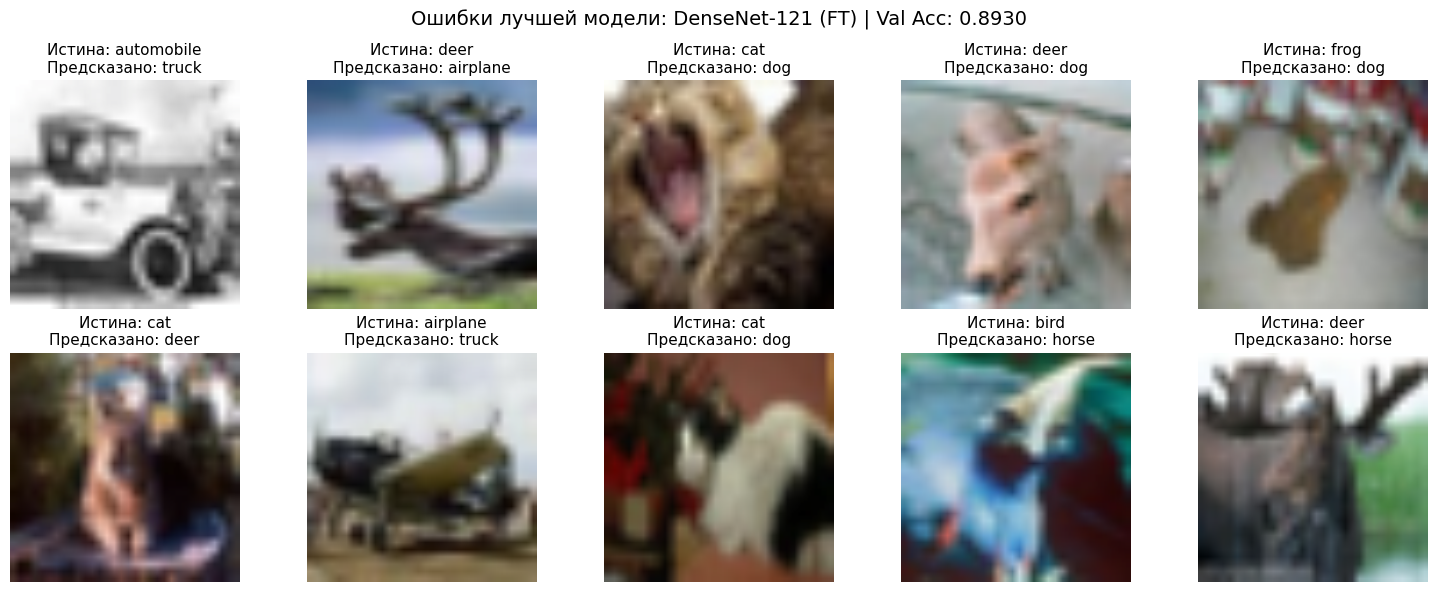

In [14]:
all_bests = [
    {**best_fe, "mode": "FE"},
    {**best_ft, "mode": "FT"},
    {**best_scratch, "mode": "Scratch"}
]
best_overall = max(all_bests, key=lambda x: x["acc"])

preds = best_overall["preds"]
labels = best_overall["labels"]
error_indices = [i for i, (p, l) in enumerate(zip(preds, labels)) if p != l][:10]

mean = np.array(IMAGENET_MEAN)
std = np.array(IMAGENET_STD)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle(
    f"Ошибки лучшей модели: {best_overall['name']} ({best_overall['mode']}) | Val Acc: {best_overall['acc']:.4f}",
    fontsize=14
)

for ax, idx in zip(axes.flat, error_indices):
    img_tensor, _ = val_ds[idx]
    img = img_tensor.permute(1, 2, 0).numpy()
    img = np.clip(img * std + mean, 0, 1)

    true_label = CLASS_NAMES[labels[idx]]
    pred_label = CLASS_NAMES[preds[idx]]

    ax.imshow(img)
    ax.set_title(f"Истина: {true_label}\nПредсказано: {pred_label}", fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Выводы

## По моделям

### ResNet-18
- FT: 0.8830 (полное 231.3 с; максимум 0.9040 на 7-й эпохе ≈161.9 с, к 10-й - 0.8830)
- FE: 0.7950 (полное 184.5 с; лучший результат на 10-й эпохе, выраженного плато нет)
- Scratch: 0.7480 (полное 365.9 с; не насыщается)
- Лучший = FT. Он опережает FE на 0.0880 и Scratch на 0.1350. Полное время FT больше FE на 46.8 с, но при ранней остановке на 7-й эпохе FT даёт 0.9040 примерно за 162 с - то есть быстрее полного FE и с заметно лучшей точностью.

### DenseNet-121
- FT: 0.8930 (полное 357.8 с; лучший результат на 10-й эпохе, плато не выражено)
- FE: 0.7960 (полное 343.0 с; максимум 0.8050 на 8-й эпохе ≈274.4 с, к 10-й - 0.7960)
- Scratch: 0.7570 (полное 811.6 с; не насыщается)
- Лучший = FT. Опережает FE на 0.0970 и Scratch на 0.1360. Полное время FT на 14.8 с больше FE, но точность выше почти на 0.1; даже лучшая эпоха FE (0.8050) уступает FT.

### EfficientNet-B0
- FT: 0.8580 (полное 279.8 с; лучший результат на 10-й эпохе, к 8-й эпохе уже 0.8550 ~223.8 с)
- FE: 0.8270 (полное 291.0 с; максимум 0.8360 на 8-й эпохе ~232.8 с, к 10-й - 0.8270)
- Scratch: 0.7360 (полное 733.8 с; не насыщается)
- Лучший = FT. Опережает FE на 0.0310 по финальной точности и на 0.0220 по лучшей эпохе, при этом полное время FT даже немного меньше FE. Для EfficientNet-B0 FT выгоднее и по точности, и по времени.

## По методам

### Feature Extraction:
- EfficientNet-B0: 0.8270 (полное 291.0 с; максимум 0.8360 на 8-й эпохе ≈232.8 с)
- DenseNet-121: 0.7960 (полное 343.0 с; максимум 0.8050 на 8-й эпохе ≈274.4 с)
- ResNet-18: 0.7950 (полное 184.5 с; лучший результат на 10-й эпохе)
- Лучший по точности = EfficientNet-B0. Он опережает DenseNet-121 на 0.0310 и ResNet-18 на 0.0320. При этом ResNet-18 остаётся самым быстрым, но уступает EfficientNet-B0 по качеству.

### Fine-Tuning:
- DenseNet-121: 0.8930 (полное 357.8 с; лучший результат на 10-й эпохе)
- ResNet-18: 0.8830 (полное 231.3 с; максимум 0.9040 на 7-й эпохе ≈161.9 с)
- EfficientNet-B0: 0.8580 (полное 279.8 с; лучший результат на 10-й эпохе)
- Лучший по финальной точности = DenseNet-121, но разрыв с ResNet-18 всего 0.0100. По соотношению точность/время выгоднее ResNet-18: на 7-й эпохе он даёт 0.9040 примерно за 162 с, тогда как DenseNet-121 достигает 0.8930 за 357.8 с. EfficientNet-B0 отстаёт от лидера на 0.0350.

### From Scratch:
- DenseNet-121: 0.7570 (полное 811.6 с; не насыщается)
- ResNet-18: 0.7480 (полное 365.9 с; не насыщается)
- EfficientNet-B0: 0.7360 (полное 733.8 с; не насыщается)
- Лучший по точности = DenseNet-121. Он опережает ResNet-18 на 0.0090, но тратит в 2.2 раза больше времени (811.6 с против 365.9 с). ResNet-18 даёт почти тот же уровень качества заметно быстрее. Все три модели не вышли на плато - для честного Scratch данных и эпох недостаточно.

## Главное
- FT > FE > Scratch для каждой архитектуры без исключений.
- Лучшая по итоговой таблице - FT DenseNet-121: 0.8930 за 357.8 с.
- По соотношению точность/время выгоднее FT ResNet-18: на 7-й эпохе 0.9040 примерно за 162 с, что выше итогового результата DenseNet-121 и более чем в 2 раза быстрее.
- FE EfficientNet-B0 - лучший вариант среди FE по точности, но ResNet-18 в FE быстрее при небольшом отставании.
- Scratch во всех случаях заметно слабее и не успевает насытиться за 10 эпох.

## Матрицы ошибок
- cat/dog - устойчивая проблема во всех режимах; с ростом качества модели она уменьшается количественно, но полностью не исчезает. Для CIFAR-10 при 32×32 это структурная сложность: класса cat и dog часто недостаточно различимы по форме и контексту.
- FE vs FT: FT заметно сокращает шумные и случайные ошибки, оставляя в основном семантически близкие пары вроде cat/dog и deer/horse. FE чаще путает классы по фону и отдельным признакам.
- From Scratch: ошибки носят более хаотичный характер, модель чаще путает далёкие классы, что говорит о невыученных базовых признаках и попытке опираться на цвет/фон, а не на форму объекта.